# Predicción de rotación de productos
### Proyecto Final · Data Science II: Machine Learning para la Ciencia de Datos

**Autora:** Vicleniz Luque

## ¿De qué trata este proyecto?
Con datos reales de ventas de una empresa (enero a septiembre de 2026), buscamos responder: **¿qué hace que un producto rote mucho o poco?** Se calculó la rotación de 1.269 productos, se los segmentó con clustering (K-Means) y se entrenó un modelo de clasificación que predice si un producto será de **Alta o Baja rotación**.

## Qué vas a encontrar en este notebook
1. **Formulación del problema y carga de datos**
2. **Exploración y limpieza (EDA):** nulos, outliers, gráficos y correlaciones
3. **Clustering:** segmentación de productos con K-Means y PCA
4. **Clasificación:** ingeniería de atributos, comparación de modelos (Regresión Logística, Random Forest, XGBoost), optimización de hiperparámetros, evaluación y explicabilidad con SHAP
5. **Conclusiones**
6. **Presentación del proyecto:** resumen en 10 diapositivas (al final)

## Materiales
- **Dataset final:** https://docs.google.com/spreadsheets/d/1QbBgeodmfoMpiWJ1LUx0GgAqImKYIjRz/edit?gid=1209389706#gid=1209389706

- **Presentación en PDF:** https://drive.google.com/file/d/1kzXNacZIInFo-AOGoc6SpA41eNtXXolJ/view?usp=sharing

## Cómo ejecutarlo
Entorno de ejecución → **Ejecutar todas**. El notebook descarga el dataset automáticamente desde Drive, así que no hace falta subir ningún archivo.

*Nota: los nombres de las marcas están anonimizados (Marca_001, Marca_002, etc.) por confidencialidad de la empresa.*

## Formulación del problema

**Tarea.** Clasificación binaria supervisada, complementada con un clustering exploratorio (no supervisado) para segmentar el catálogo.

**Variable objetivo.** `rotacion_categoria`: **Alta** (1) o **Baja** (0). La rotación de cada producto se calcula como *unidades vendidas ÷ stock* (enero a septiembre de 2026) y se clasifica según la mediana del catálogo, por lo que las clases quedan 50/50 por construcción.

**Variables predictoras.** Solo características del producto conocidas *antes* de comprarlo: precio, costo, margen, comisión, peso, marca, categoría y tipo de publicación. **Se excluyen `stock_consolidado` y `transacciones`** porque la rotación se calcula a partir de ellas y el modelo solo "redescubriría" la fórmula (fuga de datos).

**Relevancia para el negocio.** Comprar de más un producto que rota poco inmoviliza capital y genera sobrestock. Un modelo que anticipe la rotación permite ajustar las compras y priorizar la reposición.

**Métricas de éxito.**
- **ROC-AUC (principal):** mide qué tan bien el modelo ordena los productos de mayor a menor probabilidad de rotar mucho, sin depender de un umbral. Sirve para priorizar compras. Un modelo sin información daría 0,50.
- **Recall de la clase Baja y F1:** el error más costoso es no detectar un producto de Baja rotación (se compra de más). Por eso se mira cuántos de los productos Baja logra detectar el modelo, sin perder precisión.
- **Accuracy:** se reporta como referencia; con clases balanceadas es interpretable (el azar da 50%).

**Origen de los datos.** Se cruzaron por SKU tres fuentes de la empresa (ventas aprobadas, maestro de productos y publicaciones de MercadoLibre). El dataset final ya integrado se descarga automáticamente al ejecutar el notebook. Los costos en USD se convirtieron con un dólar fijo de $1.540 y las marcas están anonimizadas.

In [131]:
# Instalar dependencias que Colab no trae por defecto
!pip install -q shap xgboost gdown openpyxl

# Importar librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import re

In [132]:
FILE_ID = "1QbBgeodmfoMpiWJ1LUx0GgAqImKYIjRz"

try:
    # Si es una hoja de Google, se descarga como Excel directamente
    url = f"https://docs.google.com/spreadsheets/d/{FILE_ID}/export?format=xlsx"
    df = pd.read_excel(url, sheet_name="Dataset_Final")
except Exception:
    # Si es un .xlsx subido a Drive, se descarga con gdown
    !gdown {FILE_ID} -O dataset_final_proyecto.xlsx
    df = pd.read_excel("dataset_final_proyecto.xlsx", sheet_name="Dataset_Final")

df.shape

(1282, 17)

In [133]:
df.head()

,sku,nombre_producto,categoria,marca_anon,costo,costo_moneda_detectada,precio_default,precio_unitario_promedio,margen_pct,stock_consolidado,unidades_vendidas,transacciones,rotacion_mensual,rotacion_categoria,peso_g,comision_pct,tipo_publicacion
0,002001,Banquito Banqueta en Acero Plegable Playa Camp...,"Deportes y Fitness > Camping, Caza y Pesca > E...",Marca_035,7863.548,USD->ARS,32990.0,14494.333333,0.457474,147,3,2,0.002408,Baja,3761.0,0.160,Clásica
1,002004,Silla Plegable Mor 4 Posiciones Acero Liviana ...,"Hogar, Muebles y Jardín > Jardin y Aire Libre ...",Marca_035,22752.114,USD->ARS,100190.0,43844.500000,0.481073,277,4,2,0.001704,Baja,NaN,0.140,Clásica
2,002004-PR,Silla Plegable Mor 4 Posiciones Acero Liviana ...,"Hogar, Muebles y Jardín > Jardin y Aire Libre ...",Marca_035,22752.114,USD->ARS,165309.0,59399.000000,0.616961,277,3,1,0.001278,Baja,NaN,0.229,Premium
3,002005,Silla Plegable De Acero 8 Posiciones Mor Color...,"Hogar, Muebles y Jardín > Jardin y Aire Libre ...",Marca_035,22174.460,USD->ARS,71512.0,48607.500000,0.543806,330,4,3,0.001430,Baja,NaN,0.140,Clásica
4,002103,Silla Reclinable Aluminio Mor 4 Posiciones Col...,"Hogar, Muebles y Jardín > Jardin y Aire Libre ...",Marca_035,26385.744,USD->ARS,116190.0,54656.666667,0.517246,268,3,2,0.001321,Baja,NaN,0.140,Clásica


In [134]:
nulos = df.isnull().sum().sort_values(ascending=False)
nulos = nulos[nulos > 0]
porcentaje = (nulos / len(df) * 100).round(2)
pd.DataFrame({'nulos': nulos, 'porcentaje_%': porcentaje})

,nulos,porcentaje_%
peso_g,437,34.09
tipo_publicacion,81,6.32
comision_pct,81,6.32
margen_pct,13,1.01
costo_moneda_detectada,6,0.47
precio_default,6,0.47
costo,6,0.47


In [135]:
df_clean = df.copy()

# Eliminar filas sin costo/margen (menos del 1% del dataset)
df_clean = df_clean.dropna(subset=['costo', 'margen_pct'])

# Imputar peso con la mediana (no es crítica, evitamos perder filas)
df_clean['peso_g'] = df_clean['peso_g'].fillna(df_clean['peso_g'].median())

# Imputar comisión con la mediana, y tipo_publicacion con una categoría explícita
df_clean['comision_pct'] = df_clean['comision_pct'].fillna(df_clean['comision_pct'].median())
df_clean['tipo_publicacion'] = df_clean['tipo_publicacion'].fillna('Sin dato')

print("Filas originales:", len(df))
print("Filas luego de limpieza:", len(df_clean))
df_clean.isnull().sum().sum()

Filas originales: 1282
Filas luego de limpieza: 1269


np.int64(0)

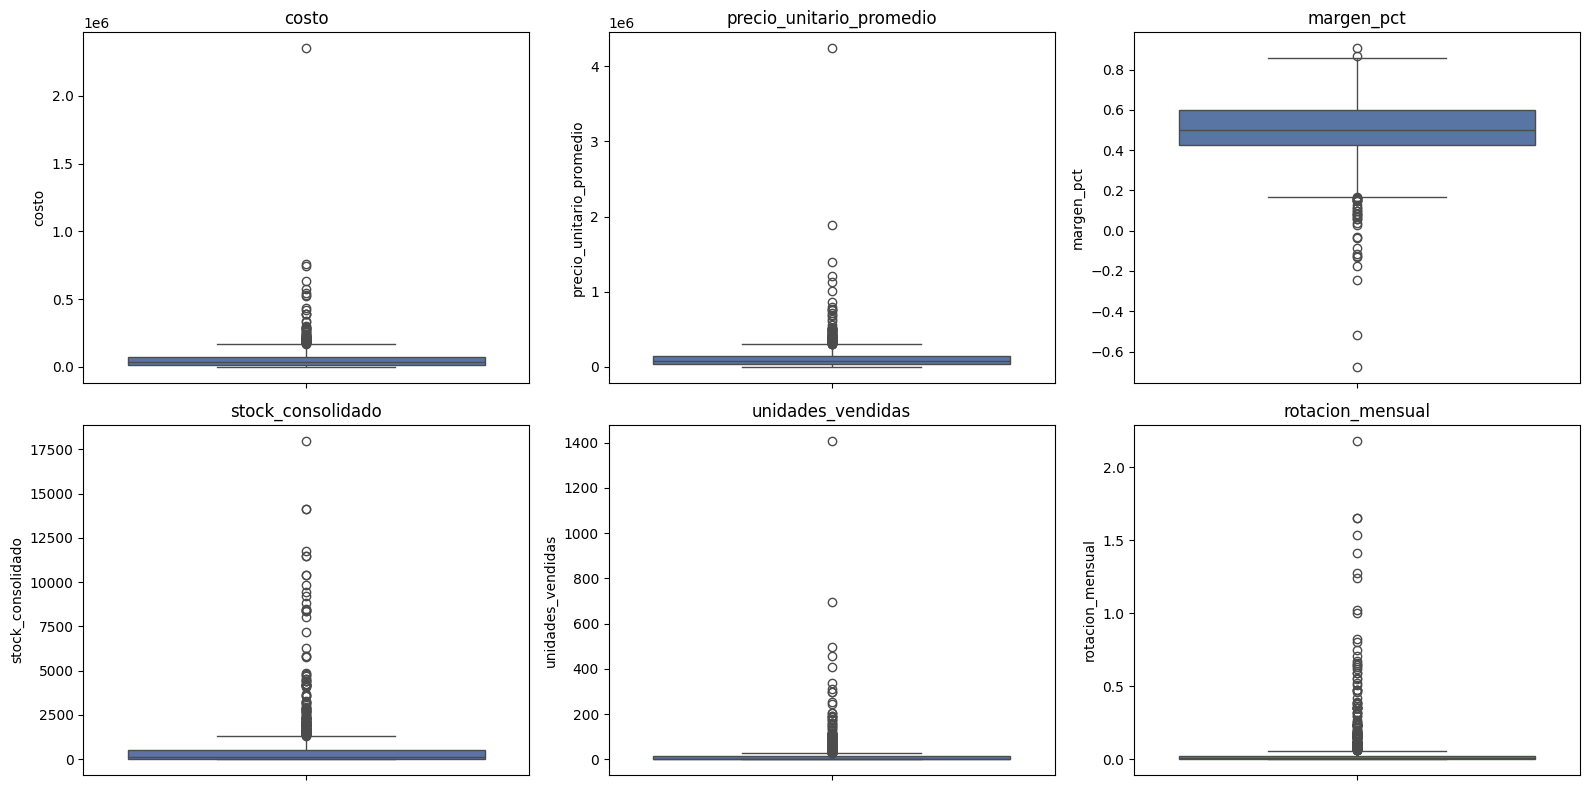

In [136]:
num_cols = ['costo', 'precio_unitario_promedio', 'margen_pct', 'stock_consolidado',
            'unidades_vendidas', 'rotacion_mensual']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color='#4C72B0')
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [137]:
def resumen_outliers(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ((serie < lim_inf) | (serie > lim_sup)).sum()

for col in num_cols:
    print(f"{col}: {resumen_outliers(df_clean[col])} outliers (regla IQR)")

costo: 84 outliers (regla IQR)
precio_unitario_promedio: 82 outliers (regla IQR)
margen_pct: 35 outliers (regla IQR)
stock_consolidado: 158 outliers (regla IQR)
unidades_vendidas: 164 outliers (regla IQR)
rotacion_mensual: 190 outliers (regla IQR)


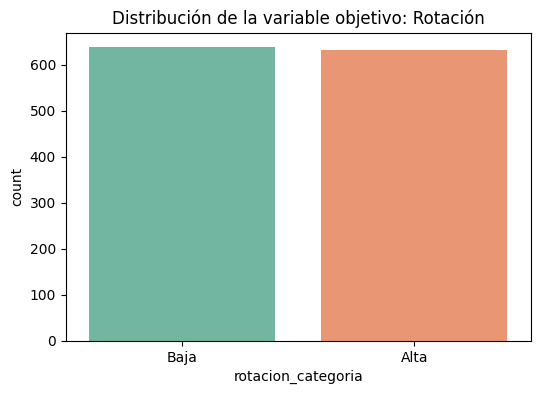

,proportion
rotacion_categoria,
Baja,50.3
Alta,49.7


In [138]:
plt.figure(figsize=(6,4))
sns.countplot(data=df_clean, x='rotacion_categoria', palette='Set2')
plt.title('Distribución de la variable objetivo: Rotación')
plt.show()

df_clean['rotacion_categoria'].value_counts(normalize=True).round(3) * 100

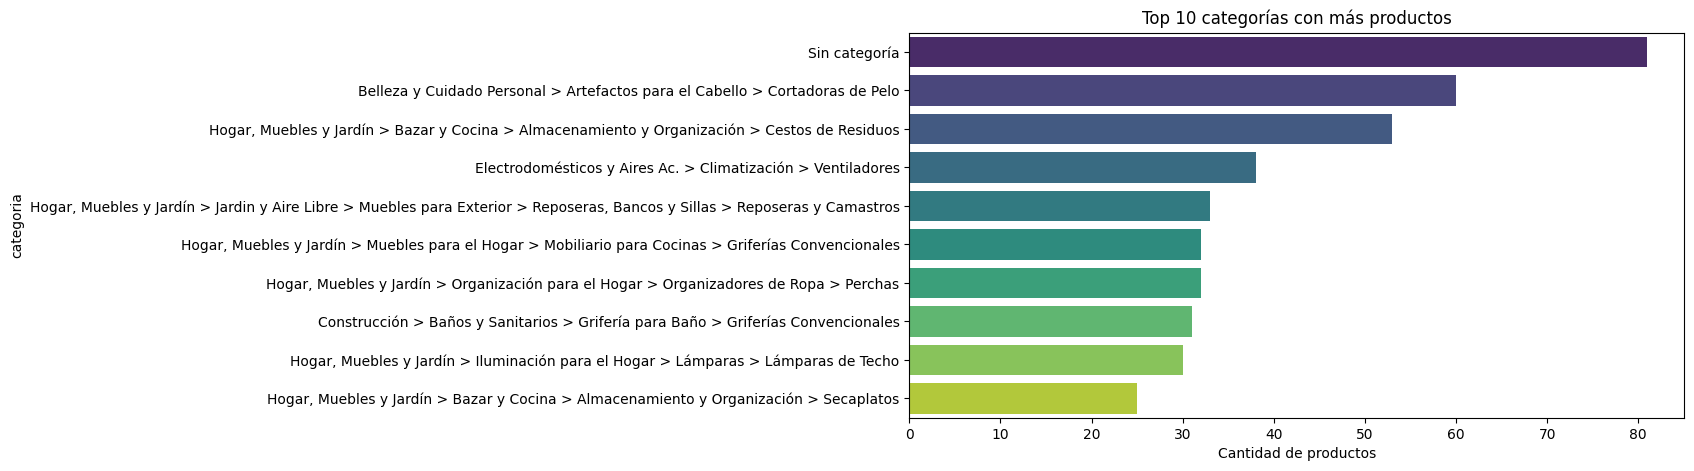

In [139]:
plt.figure(figsize=(10,5))
top_categorias = df_clean['categoria'].value_counts().head(10)
sns.barplot(x=top_categorias.values, y=top_categorias.index, palette='viridis')
plt.title('Top 10 categorías con más productos')
plt.xlabel('Cantidad de productos')
plt.show()

**Nota sobre "Sin categoría":** el 6,3% de los productos (81 de 1.282) no tienen categoría asignada porque ese dato solo existe para productos publicados en MercadoLibre. Los productos vendidos por otros canales (Fravega, Macro, Megatone, etc.) no cuentan con esa clasificación en los sistemas actuales de la empresa.

La categoría de producto solo está disponible para los ítems publicados en MercadoLibre. Los productos vendidos exclusivamente por otros canales (Fravega, Macro, Megatone, etc.) no cuentan con esa clasificación en los sistemas actuales . Una oportunidad de mejora para la empresa sería estandarizar la categorización de productos independientemente del canal de venta.

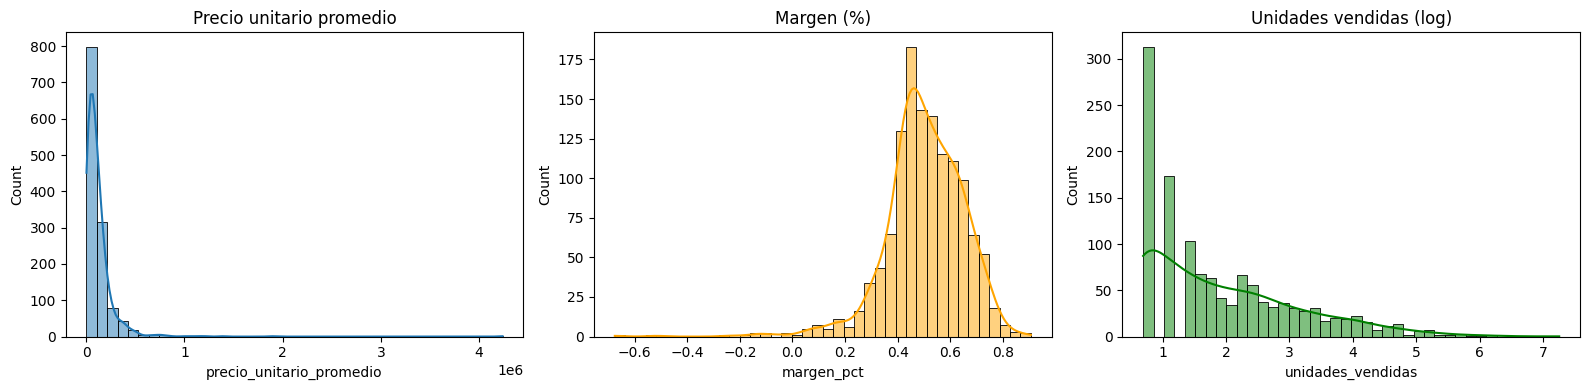

In [140]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.histplot(df_clean['precio_unitario_promedio'], bins=40, ax=axes[0], kde=True)
axes[0].set_title('Precio unitario promedio')
sns.histplot(df_clean['margen_pct'], bins=40, ax=axes[1], kde=True, color='orange')
axes[1].set_title('Margen (%)')
sns.histplot(np.log1p(df_clean['unidades_vendidas']), bins=40, ax=axes[2], kde=True, color='green')
axes[2].set_title('Unidades vendidas (log)')
plt.tight_layout()
plt.show()

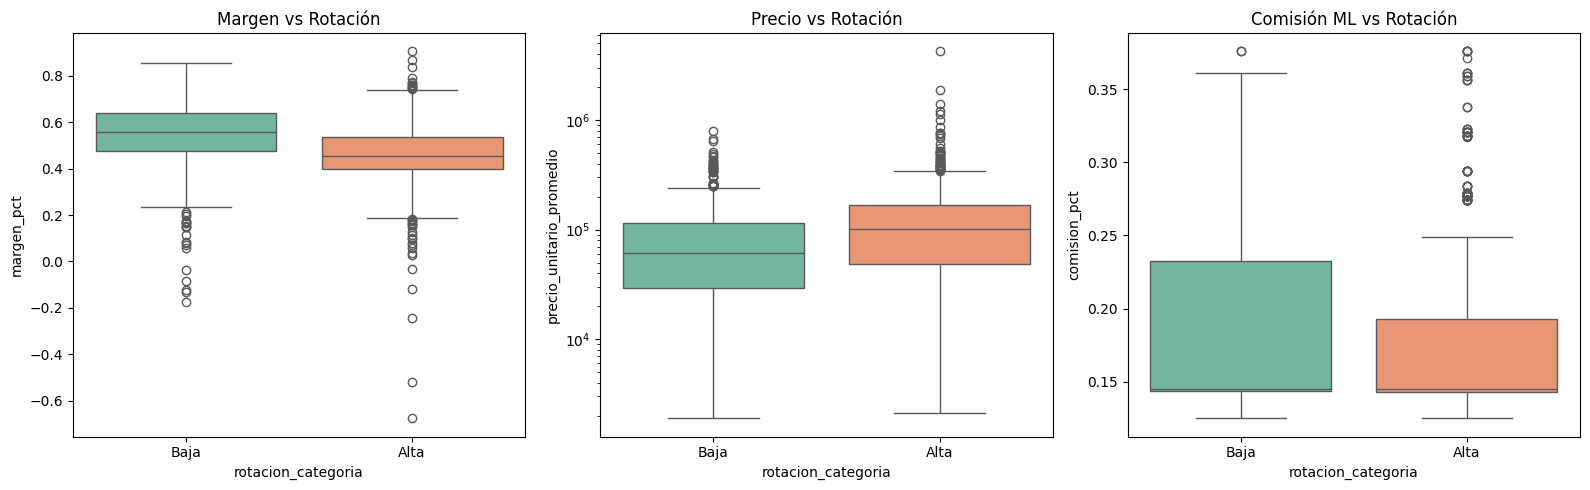

In [141]:
fig, axes = plt.subplots(1, 3, figsize=(16,5))
sns.boxplot(data=df_clean, x='rotacion_categoria', y='margen_pct', ax=axes[0], palette='Set2')
axes[0].set_title('Margen vs Rotación')
sns.boxplot(data=df_clean, x='rotacion_categoria', y='precio_unitario_promedio', ax=axes[1], palette='Set2')
axes[1].set_title('Precio vs Rotación')
axes[1].set_yscale('log')
sns.boxplot(data=df_clean, x='rotacion_categoria', y='comision_pct', ax=axes[2], palette='Set2')
axes[2].set_title('Comisión ML vs Rotación')
plt.tight_layout()
plt.show()

**Margen vs Rotación (izquierda):** los productos de Baja rotación tienen un margen más alto (mediana ~55-60%) que los de Alta rotación (mediana ~45%). Los productos que menos se venden son los que más ganancia dejan por unidad.

**Precio vs Rotación (centro):** contrario a lo que se podría esperar, los productos de Alta rotación tienden a ser más caros (mediana ~$100.000) que los de Baja (mediana ~$60.000-70.000). En este catálogo, lo barato no necesariamente se vende más.

**Comisión vs Rotación (derecha):** los productos de Baja rotación pagan una comisión de MercadoLibre algo más alta (mediana ~14,5%, con más dispersión hacia arriba) que los de Alta.

**Patrón de volumen vs. margen.** Los productos de Alta rotación son más caros y con menor margen unitario: compiten por volumen. Los de Baja rotación son más baratos y con mayor margen: son productos de nicho, donde la ganancia viene del margen por unidad y no de la cantidad vendida.

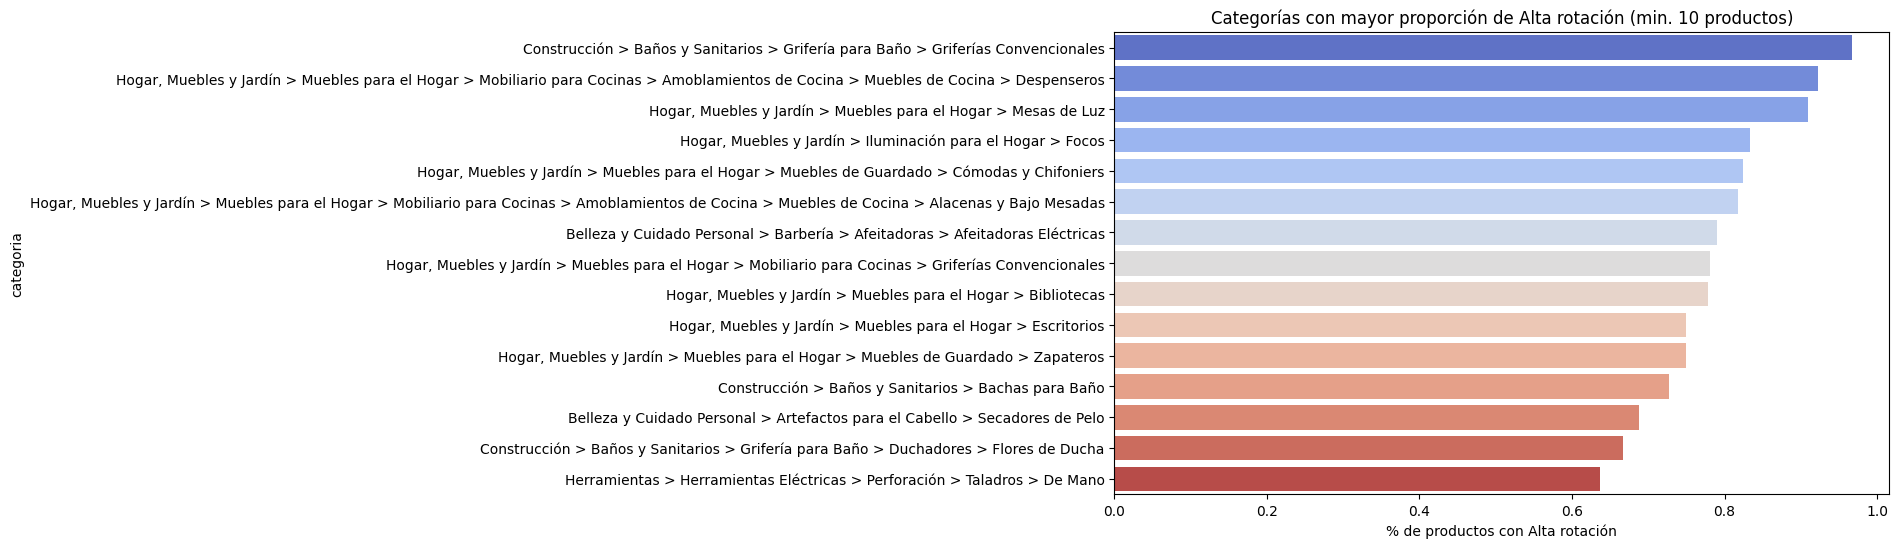

In [142]:
plt.figure(figsize=(10,6))
top_cats_rotacion = (df_clean.groupby('categoria')['rotacion_categoria']
                     .apply(lambda x: (x=='Alta').mean())
                     .sort_values(ascending=False))
top_cats_rotacion = top_cats_rotacion[df_clean['categoria'].value_counts() >= 10].head(15)
sns.barplot(x=top_cats_rotacion.values, y=top_cats_rotacion.index, palette='coolwarm')
plt.xlabel('% de productos con Alta rotación')
plt.title('Categorías con mayor proporción de Alta rotación (min. 10 productos)')
plt.show()

**Insight accionable:** la empresa podría priorizar la reposición de stock en las categorías de Hogar/Muebles y Griferías de Baño, que concentran la mayor proporción de productos de Alta rotación.

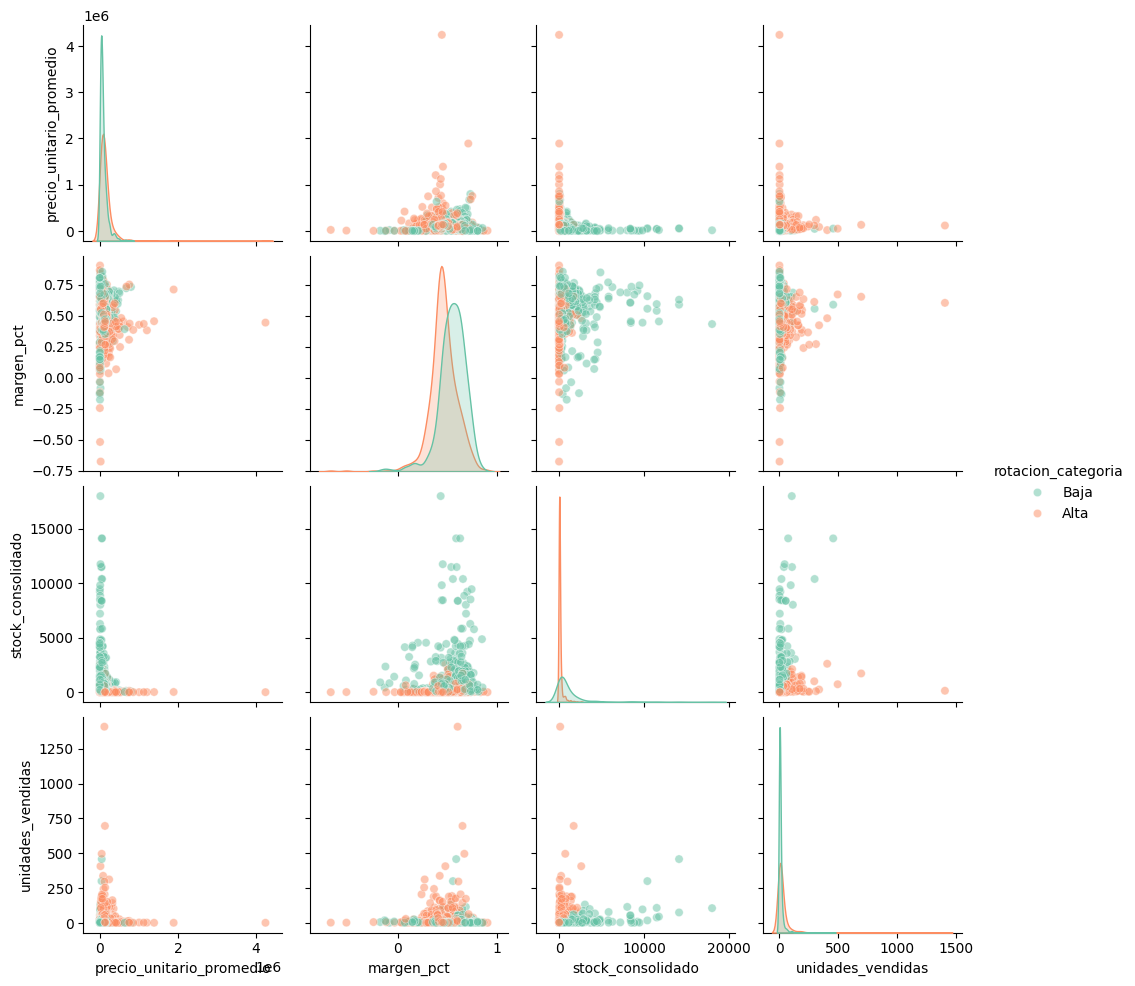

In [143]:
sns.pairplot(df_clean, vars=['precio_unitario_promedio','margen_pct','stock_consolidado','unidades_vendidas'],
             hue='rotacion_categoria', palette='Set2', diag_kind='kde', plot_kws={'alpha':0.5})
plt.show()

El análisis bivariado no mostró una separación clara entre clases con una sola variable, lo que sugiere que la clasificación requiere un modelo que combine múltiples variables.

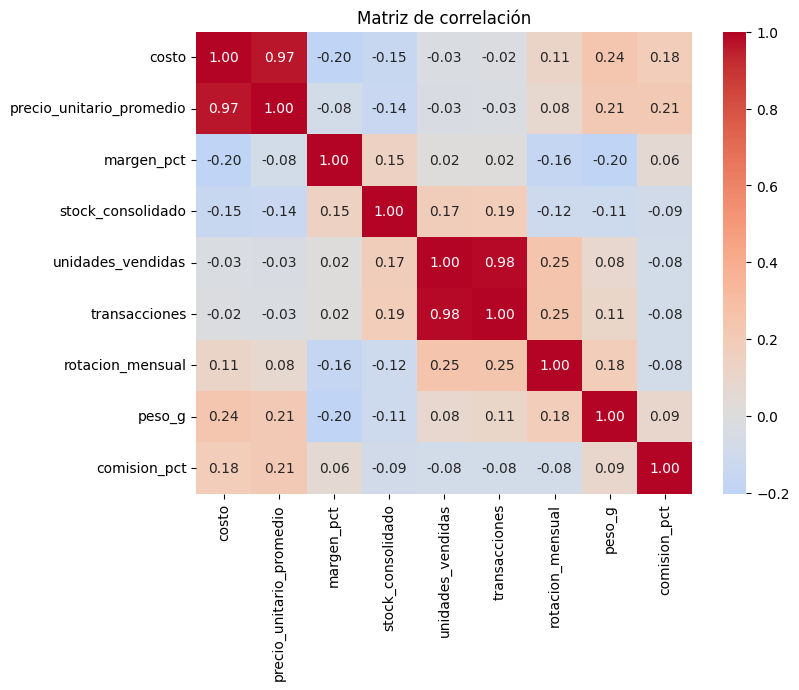

In [144]:
plt.figure(figsize=(8,6))
corr = df_clean[['costo','precio_unitario_promedio','margen_pct','stock_consolidado',
                  'unidades_vendidas','transacciones','rotacion_mensual','peso_g','comision_pct']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()

**Fin del EDA.** Se guarda el dataset limpio para el modelado.

In [145]:
df_clean.to_csv('dataset_limpio.csv', index=False)
print("Dataset limpio guardado:", df_clean.shape)

Dataset limpio guardado: (1269, 17)


In [146]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Clasificación
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, roc_auc_score, RocCurveDisplay)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [147]:
cluster_vars = ['precio_unitario_promedio', 'margen_pct', 'stock_consolidado', 'transacciones']

X_cluster = StandardScaler().fit_transform(df_clean[cluster_vars])
print("Forma de los datos para clustering:", X_cluster.shape)

Forma de los datos para clustering: (1269, 4)


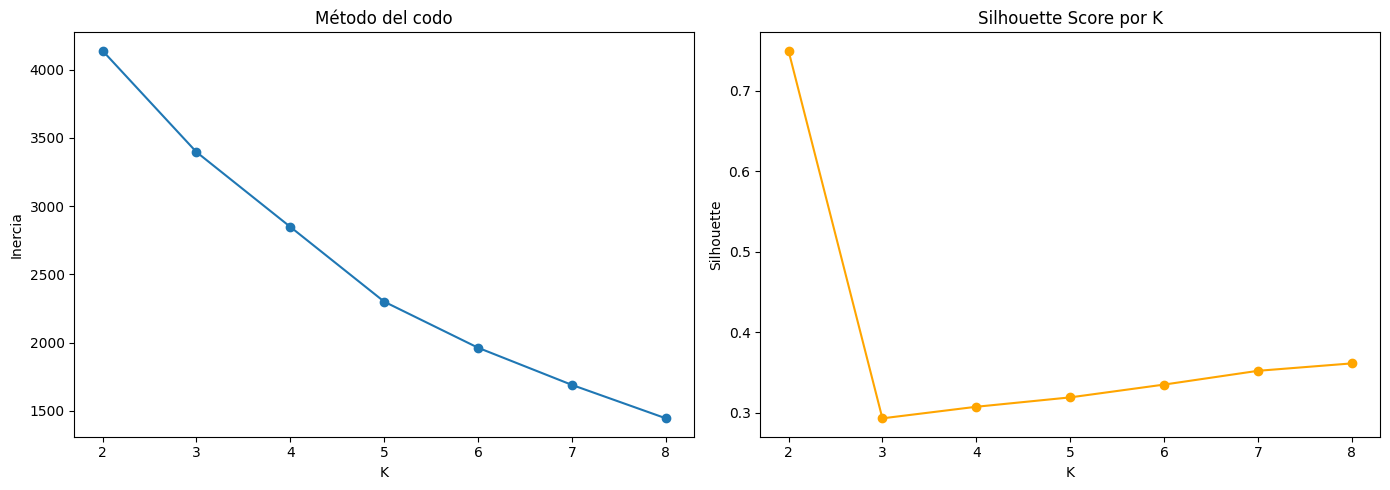

,K,inercia,silhouette
0,2,4139.981721,0.750003
1,3,3396.941003,0.292939
2,4,2847.899591,0.307329
3,5,2299.484675,0.318996
4,6,1961.536468,0.334905
5,7,1688.988567,0.352029
6,8,1444.022474,0.361261


In [148]:
inertias, silhouettes = [], []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10).fit(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('K'); axes[0].set_ylabel('Inercia')

axes[1].plot(list(k_range), silhouettes, marker='o', color='orange')
axes[1].set_title('Silhouette Score por K')
axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

pd.DataFrame({'K': list(k_range), 'inercia': inertias, 'silhouette': silhouettes})

In [149]:
for k in [3, 4, 5, 6]:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10).fit(X_cluster)
    tamanos = pd.Series(km.labels_).value_counts().sort_index().tolist()
    print(f"K={k}: tamaños de los grupos = {tamanos}")

K=3: tamaños de los grupos = [624, 27, 618]
K=4: tamaños de los grupos = [629, 23, 581, 36]
K=5: tamaños de los grupos = [23, 613, 23, 5, 605]
K=6: tamaños de los grupos = [580, 23, 23, 69, 1, 573]


In [150]:
K_OPTIMO = 3

kmeans_final = KMeans(n_clusters=K_OPTIMO, random_state=RANDOM_SEED, n_init=10)
df_clean['cluster'] = kmeans_final.fit_predict(X_cluster)

print("Silhouette:", round(silhouette_score(X_cluster, df_clean['cluster']), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_cluster, df_clean['cluster']), 1))
print("Davies-Bouldin:", round(davies_bouldin_score(X_cluster, df_clean['cluster']), 3))

perfil = df_clean.groupby('cluster')[cluster_vars].mean().round(2)
perfil['n_productos'] = df_clean['cluster'].value_counts().sort_index()
perfil

Silhouette: 0.293
Calinski-Harabasz: 312.9
Davies-Bouldin: 1.166


,precio_unitario_promedio,margen_pct,stock_consolidado,transacciones,n_productos
cluster,,,,,
0,81847.80,0.61,676.84,13.47,624
1,36755.53,0.61,8340.59,136.44,27
2,155057.31,0.39,206.10,13.10,618


**Grupo 1 (27 productos atípicos):** son los productos de mayor volumen: los más baratos, con ~10 veces más transacciones y ~12 veces más stock que el resto. Son el 2% del catálogo.

**Grupos 0 y 2:** venden casi igual (13,5 vs 13,1 transacciones). Los separa el modelo de negocio: el grupo 0 es de margen alto con precio medio y el grupo 2 es de precio alto con margen bajo. Esto conecta con la tensión entre volumen y margen vista en el EDA.

**Métricas de calidad:** el silhouette de 0,29 es modesto: los grupos existen pero se superponen en parte. Davies-Bouldin 1,17 también indica separación moderada (más cerca de 0 sería mejor). Calinski-Harabasz (312,9) solo sirve para comparar entre distintos K; no tiene una escala de bueno o malo.

In [151]:
pd.crosstab(df_clean['cluster'], df_clean['rotacion_categoria'], normalize='index').round(2)

rotacion_categoria,Alta,Baja
cluster,,
0,0.33,0.67
1,0.15,0.85
2,0.68,0.32


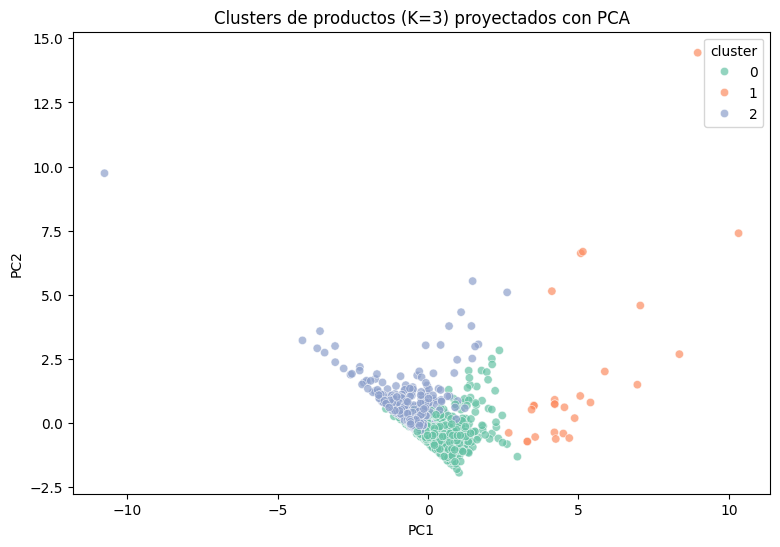

Varianza explicada por PC1+PC2: 58.1%


In [152]:
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_cluster)
df_clean['PC1'], df_clean['PC2'] = X_pca[:,0], X_pca[:,1]

plt.figure(figsize=(9,6))
sns.scatterplot(data=df_clean, x='PC1', y='PC2', hue='cluster', palette='Set2', alpha=0.7)
plt.title('Clusters de productos (K=3) proyectados con PCA')
plt.show()

print(f"Varianza explicada por PC1+PC2: {pca.explained_variance_ratio_.sum()*100:.1f}%")

Se aplicó K-Means con K=3 sobre precio, margen, stock y transacciones estandarizados. K=2 se descartó porque aislaba solo 27 productos atípicos (silhouette inflado de 0.75). Resultaron tres segmentos: productos de precio medio y margen alto (624), productos de precio alto y margen bajo (618), y 27 productos de alto volumen, bajo precio y mucho stock, que en su mayoría figuran como baja rotación por sobrestock. El silhouette (0.29) indica separación moderada: los dos grupos grandes se superponen.

In [153]:
df_clean['categoria_principal'] = df_clean['categoria'].str.split(' > ').str[0]
print(df_clean['categoria_principal'].value_counts())

y = df_clean['rotacion_categoria'].map({'Baja': 0, 'Alta': 1})

num_features = ['precio_unitario_promedio', 'margen_pct', 'comision_pct', 'peso_g']
cat_features = ['categoria_principal', 'marca_anon', 'tipo_publicacion']

X = pd.concat([df_clean[num_features],
               pd.get_dummies(df_clean[cat_features], drop_first=True)], axis=1)
print("Forma de X:", X.shape)

categoria_principal
Hogar, Muebles y Jardín          596
Belleza y Cuidado Personal       182
Electrodomésticos y Aires Ac.    175
Sin categoría                     81
Construcción                      81
Herramientas                      62
Deportes y Fitness                38
Computación                       18
Industrias y Oficinas             14
Juegos y Juguetes                  7
Accesorios para Vehículos          4
Salud y Equipamiento Médico        3
Celulares y Teléfonos              2
Electrónica, Audio y Video         2
Consolas y Videojuegos             1
Mascotas                           1
Souvenirs, Cotillón y Fiestas      1
Agro                               1
Name: count, dtype: int64
Forma de X: (1269, 86)


In [154]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Escalar solo las numéricas (el escalador aprende únicamente de train)
scaler = StandardScaler()
X_train_sc, X_test_sc = X_train.copy(), X_test.copy()
X_train_sc[num_features] = scaler.fit_transform(X_train[num_features])
X_test_sc[num_features] = scaler.transform(X_test[num_features])

# Baseline: Regresión Logística
baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
baseline.fit(X_train_sc, y_train)
y_pred_base = baseline.predict(X_test_sc)

print("Accuracy:", round(accuracy_score(y_test, y_pred_base), 3))
print(classification_report(y_test, y_pred_base, target_names=['Baja', 'Alta']))

Train: (1015, 86)  Test: (254, 86)
Accuracy: 0.76
              precision    recall  f1-score   support

        Baja       0.72      0.85      0.78       128
        Alta       0.82      0.67      0.73       126

    accuracy                           0.76       254
   macro avg       0.77      0.76      0.76       254
weighted avg       0.77      0.76      0.76       254



In [155]:
modelos = {
    'Regresión Logística': (LogisticRegression(max_iter=1000, random_state=RANDOM_SEED), X_train_sc, X_test_sc),
    'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED), X_train, X_test),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_SEED), X_train, X_test),
}

resultados = []
for nombre, (modelo, Xtr, Xte) in modelos.items():
    modelo.fit(Xtr, y_train)
    y_pred = modelo.predict(Xte)
    y_proba = modelo.predict_proba(Xte)[:, 1]
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    })

tabla_resultados = pd.DataFrame(resultados).sort_values('F1', ascending=False).round(3)
tabla_resultados

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Regresión Logística,0.760,0.816,0.667,0.734,0.808
1,Random Forest,0.728,0.752,0.675,0.711,0.788
2,Gradient Boosting,0.736,0.786,0.643,0.707,0.802


In [123]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score

# El escalado va dentro del pipeline para que en cada vuelta aprenda solo de su train
prep = ColumnTransformer([('num', StandardScaler(), num_features)], remainder='passthrough')

modelos_cv = {
    'Regresión Logística': make_pipeline(prep, LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

for nombre, modelo in modelos_cv.items():
    acc = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
    f1 = cross_val_score(modelo, X, y, cv=cv, scoring='f1')
    print(f"{nombre}: Accuracy = {acc.mean():.3f} (±{acc.std():.3f}) | F1 = {f1.mean():.3f} (±{f1.std():.3f})")

Regresión Logística: Accuracy = 0.749 (±0.020) | F1 = 0.728 (±0.022)
Random Forest: Accuracy = 0.726 (±0.016) | F1 = 0.716 (±0.014)
Gradient Boosting: Accuracy = 0.731 (±0.018) | F1 = 0.707 (±0.022)


Mejor parámetro: {'logisticregression__C': 10} | F1 en validación cruzada: 0.734
Accuracy en test: 0.756
              precision    recall  f1-score   support

        Baja       0.73      0.83      0.77       128
        Alta       0.80      0.68      0.74       126

    accuracy                           0.76       254
   macro avg       0.76      0.76      0.75       254
weighted avg       0.76      0.76      0.75       254



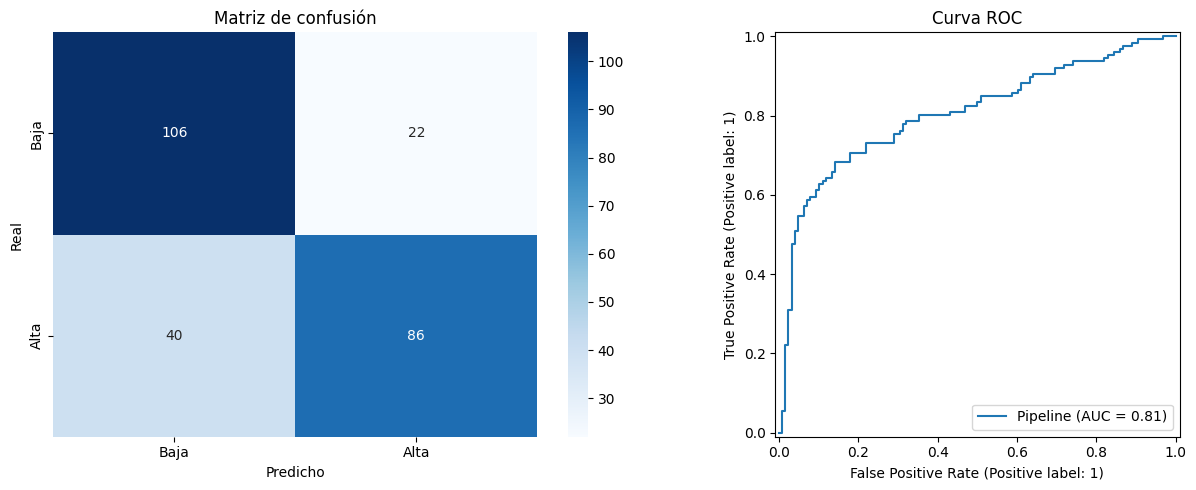

In [124]:
param_grid = {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}
pipe = make_pipeline(prep, LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1')
grid.fit(X_train, y_train)
print("Mejor parámetro:", grid.best_params_, "| F1 en validación cruzada:", round(grid.best_score_, 3))

mejor_modelo = grid.best_estimator_
y_pred_final = mejor_modelo.predict(X_test)
print("Accuracy en test:", round(accuracy_score(y_test, y_pred_final), 3))
print(classification_report(y_test, y_pred_final, target_names=['Baja', 'Alta']))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_test, y_pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Baja', 'Alta'], yticklabels=['Baja', 'Alta'], ax=axes[0])
axes[0].set_xlabel('Predicho'); axes[0].set_ylabel('Real'); axes[0].set_title('Matriz de confusión')
RocCurveDisplay.from_estimator(mejor_modelo, X_test, y_test, ax=axes[1])
axes[1].set_title('Curva ROC')
plt.tight_layout()
plt.show()

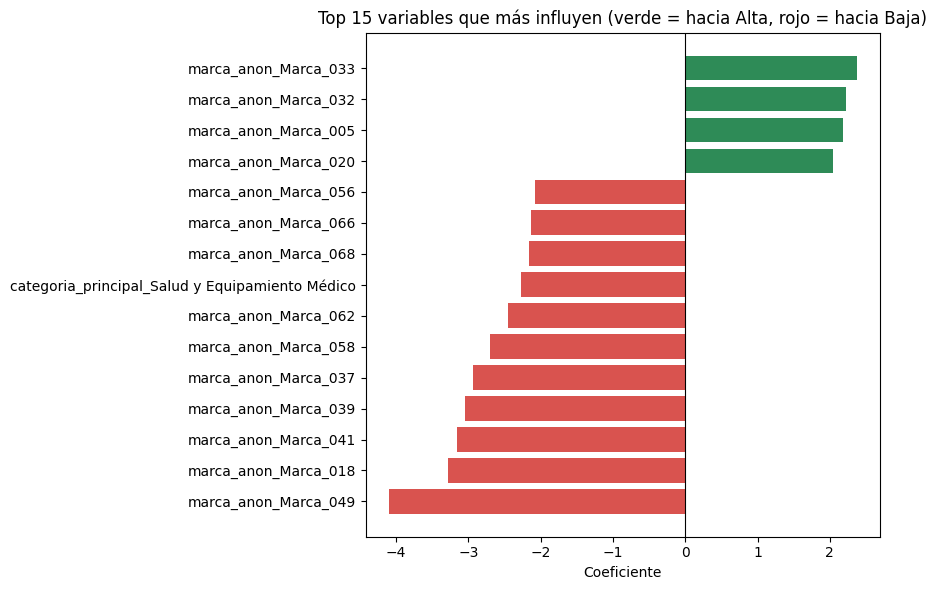

In [125]:
coefs = mejor_modelo.named_steps['logisticregression'].coef_[0]
nombres = mejor_modelo.named_steps['columntransformer'].get_feature_names_out()
nombres = [n.split('__', 1)[1] for n in nombres]

importancia = pd.Series(coefs, index=nombres)
top = importancia.reindex(importancia.abs().sort_values(ascending=False).head(15).index).sort_values()

plt.figure(figsize=(9, 6))
colores = ['#d9534f' if v < 0 else '#2e8b57' for v in top.values]
plt.barh(top.index, top.values, color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 variables que más influyen (verde = hacia Alta, rojo = hacia Baja)')
plt.xlabel('Coeficiente')
plt.tight_layout()
plt.show()

In [126]:
print("Variables numéricas (estandarizadas):")
print(importancia[num_features].round(2).sort_values())

marcas_top = ['Marca_033','Marca_032','Marca_005','Marca_020','Marca_056','Marca_066','Marca_068',
              'Marca_062','Marca_058','Marca_037','Marca_039','Marca_041','Marca_018','Marca_049']

resumen = (df_clean[df_clean['marca_anon'].isin(marcas_top)]
           .groupby('marca_anon')['rotacion_categoria']
           .agg(n_productos='count', pct_alta=lambda s: round((s == 'Alta').mean() * 100)))
print("\nMarcas destacadas del gráfico:")
print(resumen.sort_values('n_productos'))

Variables numéricas (estandarizadas):
margen_pct                 -0.50
comision_pct                0.07
precio_unitario_promedio    0.10
peso_g                      0.18
dtype: float64

Marcas destacadas del gráfico:
            n_productos  pct_alta
marca_anon                       
Marca_066             1         0
Marca_041             2         0
Marca_056             2        50
Marca_062             2         0
Marca_058             2         0
Marca_018             3         0
Marca_032             4       100
Marca_020             8       100
Marca_033             9       100
Marca_049            10         0
Marca_037            10         0
Marca_005            12        92
Marca_039            36        31
Marca_068            43        23


**Nota de interpretación:** como la rotación es ventas ÷ stock, una marca puede salir “Baja” no porque sus productos se vendan mal, sino porque se compró de más. Es decir, el efecto de la marca puede reflejar la política de compra y no la demanda.

In [127]:
# Agrupar marcas con menos de 10 productos como 'Otras'
conteo_marcas = df_clean['marca_anon'].value_counts()
marcas_frecuentes = conteo_marcas[conteo_marcas >= 10].index
df_clean['marca_agrupada'] = df_clean['marca_anon'].where(df_clean['marca_anon'].isin(marcas_frecuentes), 'Otras')
print("Marcas frecuentes:", len(marcas_frecuentes), "| Productos en 'Otras':", (df_clean['marca_agrupada'] == 'Otras').sum())

cat_features_v2 = ['categoria_principal', 'marca_agrupada', 'tipo_publicacion']
X2 = pd.concat([df_clean[num_features],
                pd.get_dummies(df_clean[cat_features_v2], drop_first=True)], axis=1)
print("Forma de X2:", X2.shape)

modelo2 = make_pipeline(prep, LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))
acc2 = cross_val_score(modelo2, X2, y, cv=cv, scoring='accuracy')
f12 = cross_val_score(modelo2, X2, y, cv=cv, scoring='f1')
print(f"Con marcas agrupadas: Accuracy = {acc2.mean():.3f} (±{acc2.std():.3f}) | F1 = {f12.mean():.3f} (±{f12.std():.3f})")
modelo_ref = make_pipeline(prep, LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))
acc_ref = cross_val_score(modelo_ref, X, y, cv=cv, scoring='accuracy')
f1_ref = cross_val_score(modelo_ref, X, y, cv=cv, scoring='f1')
print(f"Referencia (marcas sin agrupar): Accuracy = {acc_ref.mean():.3f} | F1 = {f1_ref.mean():.3f}")

Marcas frecuentes: 22 | Productos en 'Otras': 128
Forma de X2: (1269, 45)
Con marcas agrupadas: Accuracy = 0.752 (±0.010) | F1 = 0.732 (±0.012)
Referencia (marcas sin agrupar): Accuracy = 0.749 | F1 = 0.728


Mejor C: {'logisticregression__C': 100} | F1 en validación cruzada: 0.731
Accuracy en test: 0.768
ROC-AUC en test: 0.808
              precision    recall  f1-score   support

        Baja       0.73      0.84      0.79       128
        Alta       0.81      0.69      0.75       126

    accuracy                           0.77       254
   macro avg       0.77      0.77      0.77       254
weighted avg       0.77      0.77      0.77       254



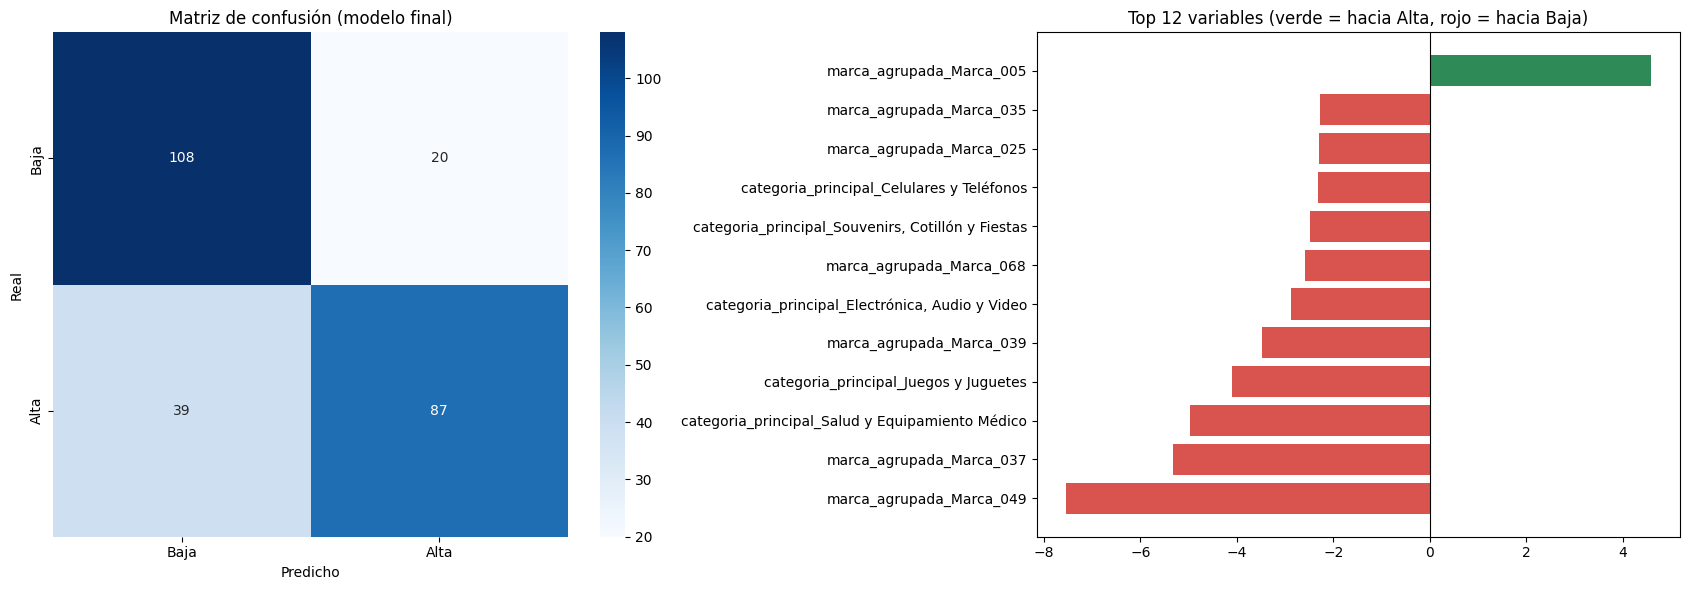

In [128]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

pipe2 = make_pipeline(prep, LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))
grid2 = GridSearchCV(pipe2, {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}, cv=cv, scoring='f1')
grid2.fit(X2_train, y2_train)
print("Mejor C:", grid2.best_params_, "| F1 en validación cruzada:", round(grid2.best_score_, 3))

modelo_final = grid2.best_estimator_
y_pred_f = modelo_final.predict(X2_test)
print("Accuracy en test:", round(accuracy_score(y2_test, y_pred_f), 3))
print("ROC-AUC en test:", round(roc_auc_score(y2_test, modelo_final.predict_proba(X2_test)[:, 1]), 3))
print(classification_report(y2_test, y_pred_f, target_names=['Baja', 'Alta']))

# Matriz de confusión + coeficientes
coefs2 = modelo_final.named_steps['logisticregression'].coef_[0]
nombres2 = [n.split('__', 1)[1] for n in modelo_final.named_steps['columntransformer'].get_feature_names_out()]
imp2 = pd.Series(coefs2, index=nombres2)
top2 = imp2.reindex(imp2.abs().sort_values(ascending=False).head(12).index).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(confusion_matrix(y2_test, y_pred_f), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Baja', 'Alta'], yticklabels=['Baja', 'Alta'], ax=axes[0])
axes[0].set_xlabel('Predicho'); axes[0].set_ylabel('Real'); axes[0].set_title('Matriz de confusión (modelo final)')
axes[1].barh(top2.index, top2.values, color=['#d9534f' if v < 0 else '#2e8b57' for v in top2.values])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Top 12 variables (verde = hacia Alta, rojo = hacia Baja)')
plt.tight_layout()
plt.show()

## Ingeniería de atributos, optimización de hiperparámetros y comparación final

Hasta acá se trabajó con los atributos originales y un modelo lineal. En esta sección se crean variables nuevas y se comparan **Regresión Logística, Random Forest y XGBoost**, optimizando los hiperparámetros de cada uno con validación cruzada (5 vueltas) y usando **ROC-AUC** como métrica a maximizar.

**Atributos nuevos y por qué se crean** (ninguno usa la variable objetivo, stock ni transacciones):
- `log_precio`, `log_costo`, `log_peso`: precio, costo y peso tienen distribuciones muy asimétricas con outliers (se vio en el EDA). El logaritmo reduce ese efecto y ayuda sobre todo al modelo lineal.
- `marca_n_productos`: cantidad de productos de cada marca en el catálogo. Resume el "tamaño" de la marca en una sola columna, en lugar de decenas de columnas dummy.
- `sin_categoria`: indica que el producto no tiene categoría (no está publicado en MercadoLibre). Es un dato faltante estructural, no aleatorio, y puede tener señal propia.

**Transformaciones ya aplicadas antes:** imputación por mediana de peso y comisión, agrupación de marcas con menos de 10 productos en "Otras", one-hot encoding de variables categóricas y estandarización de las numéricas dentro de un pipeline (para que el escalador aprenda solo del train en cada vuelta).

In [ ]:
# ============================================================
# INGENIERÍA DE ATRIBUTOS
# ============================================================
df_fe = df_clean.copy()
df_fe['log_precio'] = np.log1p(df_fe['precio_unitario_promedio'])
df_fe['log_costo'] = np.log1p(df_fe['costo'])
df_fe['log_peso'] = np.log1p(df_fe['peso_g'])
df_fe['marca_n_productos'] = df_fe['marca_anon'].map(df_fe['marca_anon'].value_counts()).fillna(1)
df_fe['sin_categoria'] = (df_fe['categoria'].isna() |
                          df_fe['categoria'].astype(str).str.contains('Sin categor', case=False)).astype(int)

num_features_v3 = ['margen_pct', 'comision_pct', 'log_precio', 'log_costo', 'log_peso',
                   'marca_n_productos', 'sin_categoria']
cat_features_v3 = ['categoria_principal', 'marca_agrupada', 'tipo_publicacion']

X3 = pd.concat([df_fe[num_features_v3],
                pd.get_dummies(df_fe[cat_features_v3], drop_first=True)], axis=1).astype(float)
# XGBoost no acepta caracteres especiales en los nombres de columnas
X3.columns = [re.sub(r'[\[\]<>]', '_', str(c)) for c in X3.columns]
print("Forma de X3:", X3.shape)

# Misma partición que el modelo anterior (mismo seed y estratificación) para comparar en igualdad de condiciones
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print("Train:", X3_train.shape, " Test:", X3_test.shape)

In [ ]:
# ============================================================
# OPTIMIZACIÓN DE HIPERPARÁMETROS (validación cruzada, métrica: ROC-AUC)
# ============================================================
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

prep3 = ColumnTransformer([('num', StandardScaler(), num_features_v3)], remainder='passthrough')

busquedas = {
    'Regresión Logística v3': GridSearchCV(
        make_pipeline(prep3, LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)),
        {'logisticregression__C': [0.01, 0.1, 1, 10, 100]},
        cv=cv, scoring='roc_auc'),
    'Random Forest v3': RandomizedSearchCV(
        RandomForestClassifier(random_state=RANDOM_SEED),
        {'n_estimators': [200, 400, 600], 'max_depth': [4, 6, 8, 12, None],
         'min_samples_leaf': [1, 3, 5, 10], 'max_features': ['sqrt', 0.3, 0.5]},
        n_iter=15, cv=cv, scoring='roc_auc', random_state=RANDOM_SEED, n_jobs=-1),
    'XGBoost v3': RandomizedSearchCV(
        XGBClassifier(eval_metric='logloss', random_state=RANDOM_SEED, n_jobs=-1),
        {'n_estimators': [100, 200, 300], 'max_depth': [2, 3, 4, 5],
         'learning_rate': [0.03, 0.05, 0.1], 'subsample': [0.7, 0.85, 1.0],
         'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 3, 5],
         'reg_lambda': [1, 5, 10]},
        n_iter=25, cv=cv, scoring='roc_auc', random_state=RANDOM_SEED, n_jobs=-1),
}

def metricas_test(nombre, auc_cv, y_true, y_pred, y_proba):
    return {'Modelo': nombre, 'AUC (CV)': auc_cv,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision (Alta)': precision_score(y_true, y_pred),
            'Recall (Alta)': recall_score(y_true, y_pred),
            'Recall (Baja)': recall_score(y_true, y_pred, pos_label=0),
            'F1 (Alta)': f1_score(y_true, y_pred),
            'ROC-AUC test': roc_auc_score(y_true, y_proba)}

filas = []
for nombre, busqueda in busquedas.items():
    busqueda.fit(X3_train, y3_train)
    print(f"{nombre} -> mejores hiperparámetros: {busqueda.best_params_}")
    filas.append(metricas_test(nombre, busqueda.best_score_, y3_test,
                               busqueda.predict(X3_test), busqueda.predict_proba(X3_test)[:, 1]))

# Referencia: modelo final de la sección anterior (atributos originales), mismo conjunto de test
auc_cv_ref = cross_val_score(modelo_final, X2_train, y2_train, cv=cv, scoring='roc_auc').mean()
filas.append(metricas_test('Regresión Logística v2 (modelo previo)', auc_cv_ref, y2_test,
                           modelo_final.predict(X2_test), modelo_final.predict_proba(X2_test)[:, 1]))

tabla_final = pd.DataFrame(filas).set_index('Modelo').round(3).sort_values('AUC (CV)', ascending=False)
tabla_final

### Criterios de selección del modelo

El modelo se elige con estos criterios, en este orden:
1. **ROC-AUC en validación cruzada** (no en test, para no "elegir mirando el examen"). Una mejora menor a 0,02 de AUC se considera un empate técnico.
2. **Interpretabilidad:** el equipo de compras necesita entender por qué el modelo marca un producto como Baja rotación. Un modelo lineal se explica con coeficientes; uno de árboles requiere SHAP.
3. **Costo de los errores:** interesa detectar los productos de Baja rotación (Recall Baja) para no comprar de más.
4. **Simplicidad y estabilidad:** con solo 254 productos de test, diferencias chicas pueden ser ruido.

In [ ]:
# Regla de decisión basada en AUC de validación cruzada
logisticos = tabla_final[tabla_final.index.str.startswith('Regresión')]
mejor_log = logisticos['AUC (CV)'].idxmax()
mejor_global = tabla_final['AUC (CV)'].idxmax()
dif = tabla_final.loc[mejor_global, 'AUC (CV)'] - tabla_final.loc[mejor_log, 'AUC (CV)']

if mejor_global == mejor_log or dif < 0.02:
    print(f"Modelo elegido: {mejor_log}. Los modelos de árboles no mejoran el AUC en más de 0,02 "
          f"(diferencia = {dif:.3f}), así que se prefiere el modelo lineal por ser más simple e interpretable.")
else:
    print(f"Modelo elegido: {mejor_global}. Mejora el AUC de validación cruzada en {dif:.3f} "
          f"respecto de la mejor Regresión Logística, una ganancia que justifica la menor interpretabilidad.")

print("\nNota: el análisis SHAP de la sección siguiente se hace sobre la Regresión Logística v2; "
      "arriba se agregó el SHAP de XGBoost para poder contrastar ambas explicaciones.")

In [ ]:
# SHAP sobre el modelo XGBoost (complementa el análisis SHAP del modelo lineal de más abajo)
import shap

xgb_best = busquedas['XGBoost v3'].best_estimator_
explainer_xgb = shap.TreeExplainer(xgb_best)
shap_values_xgb = explainer_xgb.shap_values(X3_test)
shap.summary_plot(shap_values_xgb, X3_test, max_display=12)

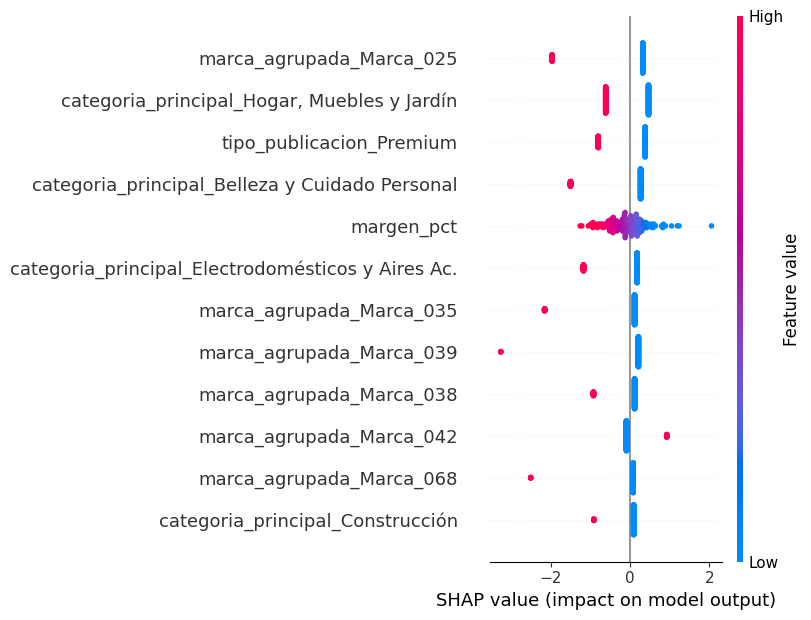

In [129]:
import shap

prep_f = modelo_final.named_steps['columntransformer']
clf = modelo_final.named_steps['logisticregression']

Xtr_t = np.asarray(prep_f.transform(X2_train), dtype=float)
Xte_t = np.asarray(prep_f.transform(X2_test), dtype=float)
nombres_shap = [n.split('__', 1)[1] for n in prep_f.get_feature_names_out()]

explainer = shap.LinearExplainer(clf, Xtr_t)
shap_values = explainer.shap_values(Xte_t)

shap.summary_plot(shap_values, Xte_t, feature_names=nombres_shap, max_display=12)

## Interpretabilidad (SHAP) y decisiones de negocio

El gráfico SHAP muestra cuánto empuja cada variable la predicción del modelo hacia Alta (derecha) o Baja (izquierda) rotación. Las variables con mayor impacto promedio son la Marca_025, la categoría Hogar/Muebles, el tipo de publicación Premium, la categoría Belleza y el margen.

- **Margen:** los puntos rojos (margen alto) quedan a la izquierda: a mayor margen, menor probabilidad de Alta rotación. Es coherente con el EDA y con el coeficiente del modelo.
- **Marca_025** (194 productos, 21% de Alta rotación): tiende a Baja rotación. Las marcas 035, 039, 038 y 068 también empujan hacia Baja.
- **Publicación Premium:** 45% de Alta rotación contra 53% en las Clásicas: no mejora la rotación.
- **Categorías:** el efecto de cada categoría se mide contra una categoría de referencia y descontando las demás variables, por eso puede diferir del porcentaje observado (Hogar: 50% de Alta; Construcción: 80% observado, pero el modelo la empuja hacia Baja una vez consideradas las demás variables).
- **Lectura del ranking:** SHAP promedia el impacto sobre los productos de test, así que una marca con pocos productos (como Marca_005, con 12) pesa poco aunque su coeficiente sea grande.

**Decisiones de negocio:**
1. Antes de comprar, revisar margen y marca: los productos de alto margen o de marcas con tendencia a Baja rotación son candidatos a comprarse en menor cantidad.
2. Evaluar si la publicación Premium se justifica, ya que no mejora la rotación.
3. Para priorizar la reposición, guiarse por la proporción de Alta rotación observada por categoría (sección de EDA) y usar el modelo para ajustar a nivel de producto.

*Limitación:* son asociaciones y no relaciones causales, y varias marcas tienen pocos productos.

In [130]:
print("Variables numéricas en el modelo final:")
print(imp2[num_features].round(2).sort_values())

marcas_plot = ['Marca_005','Marca_035','Marca_025','Marca_068','Marca_039','Marca_037','Marca_049']
res = (df_clean[df_clean['marca_agrupada'].isin(marcas_plot)]
       .groupby('marca_agrupada')['rotacion_categoria']
       .agg(n_productos='count', pct_alta=lambda s: round((s == 'Alta').mean()*100)))
print("\nMarcas del gráfico:")
print(res.sort_values('pct_alta'))

Variables numéricas en el modelo final:
margen_pct                 -0.50
precio_unitario_promedio    0.10
comision_pct                0.11
peso_g                      0.17
dtype: float64

Marcas del gráfico:
                n_productos  pct_alta
marca_agrupada                       
Marca_037                10         0
Marca_049                10         0
Marca_025               194        21
Marca_068                43        23
Marca_039                36        31
Marca_035                74        31
Marca_005                12        92


## Conclusiones

**Datos.** Se cruzaron ventas (ene-sep 2026), maestro de productos y publicaciones de MercadoLibre: 1.269 productos con stock válido. La rotación se calculó como unidades vendidas / stock, y se clasificó como Alta o Baja según la mediana (clases 50/50 por construcción).

**EDA.** Los productos de Alta rotación tienden a ser más caros y con menor margen; los de Baja rotación, más baratos y con más margen. Hogar/Muebles y Griferías de Baño concentran la mayor proporción de Alta rotación. El 6,3% de los productos no tiene categoría porque ese dato solo existe para productos publicados en MercadoLibre.

**Clustering (K-Means, K=3).** Se descartó K=2 porque aislaba solo 27 productos atípicos (silhouette inflado de 0,75). Resultaron tres segmentos: (0) 624 productos de precio medio y margen alto, mayormente Baja rotación; (2) 618 productos de precio alto y margen bajo, mayormente Alta rotación; (1) 27 productos baratos, de alto volumen y mucho stock, con 85% en Baja rotación (posible sobrestock). Silhouette 0,29 y Davies-Bouldin 1,17: separación moderada, los dos grupos grandes se superponen.

**Clasificación.** Para evitar que el modelo "redescubra" la fórmula de la rotación, se excluyeron stock y transacciones: se predijo solo con características del producto. Se compararon Regresión Logística, Random Forest y Gradient Boosting. Los tres rindieron parecido (accuracy 0,73-0,75 en validación cruzada); se eligió la Regresión Logística por simple e interpretable. Modelo final: accuracy 0,768 y ROC-AUC 0,808 en test (0,752 en validación cruzada). Detecta el 84% de los productos de Baja rotación y el 69% de los de Alta; cuando predice Alta acierta el 81%.

**Variables influyentes.** El margen es la variable numérica más relevante (a mayor margen, menor probabilidad de Alta). La marca también influye: Marca_025 (194 productos, 21% Alta) y Marca_068 (43 productos, 23%) tienden a Baja rotación. Esto puede reflejar la política de compra (sobrestock) más que la demanda.

**Recomendaciones.** (1) Revisar el stock de los 27 productos de alto volumen: venden mucho pero están sobrestockeados. (2) Usar el modelo como filtro previo a comprar: marca bien los productos con probable baja rotación. (3) Estandarizar la categorización de productos en todos los canales de venta.

**Limitaciones.** Se usó el stock actual y no el histórico; la rotación es relativa a la mediana del catálogo, no un umbral de negocio; el test tiene solo 254 productos (el accuracy puede variar unos 5 puntos); varias marcas tienen pocos productos; la conversión de costos en USD se hizo con una regla (precio/costo > 20) y un dólar fijo de $1.540; el período es de 8,5 meses.

---
# Presentación del proyecto
*Resumen en 10 diapositivas de lo que hicimos, cómo lo hicimos y qué encontramos.*

## ¿Qué hace que un producto rote mucho o poco?
### Predicción de rotación de productos con clustering y clasificación
**Vicleniz Luque** · Proyecto Final · Data Science

## Datos y enfoque

- **3 fuentes cruzadas por SKU:** ventas (ene–sep 2026), maestro de productos y publicaciones de MercadoLibre.
- **1.269 productos:** rotación = unidades vendidas ÷ stock. Alta o Baja según la mediana (50/50 por construcción).
- **Datos cuidados:** solo ventas aprobadas, costos en USD convertidos a $1.540 y marcas anonimizadas.

## Paso a paso del proyecto

1. **Cruzar fuentes:** ventas, maestro de productos y publicaciones de MercadoLibre, unidos por SKU.
2. **Limpiar:** solo ventas aprobadas, costos en USD a $1.540 y marcas anonimizadas.
3. **Calcular rotación:** unidades vendidas ÷ stock. Alta o Baja según la mediana.
4. **Explorar (EDA):** nulos, outliers, gráficos y correlaciones.
5. **Segmentar:** K-Means. Se descartó K=2 y se eligió K=3.
6. **Predecir:** tres modelos comparados con validación cruzada.

## Alta rotación: más caro y con menos margen

**Cómo lo obtuvimos:** boxplots de margen y precio según rotación, sobre 1.269 productos.

**Qué significa:**
- Alta rotación: productos más caros y con menor margen. Se gana por volumen.
- Baja rotación: productos más baratos y con mayor margen. Más de nicho.
- Hogar/Muebles y Griferías de Baño concentran la mayor proporción de Alta rotación.

## Cómo elegimos la cantidad de segmentos

**Cómo lo obtuve:** probamos K de 2 a 8 con el método del codo y el silhouette.

**Qué significa:** K=2 daba un silhouette de 0,75, pero solo separaba 27 productos atípicos, así que lo descartamos. K=3 deja dos grupos grandes y uno chico, fáciles de interpretar.

## Segmentos de productos (K-Means, K=3)

- **Precio medio, margen alto:** 624 productos, 33% de Alta rotación.
- **Precio alto, margen bajo:** 618 productos, 68% de Alta rotación.
- **Alto volumen y mucho stock:** 27 productos, 85% de Baja rotación (posible sobrestock).

**Cómo lo obtuve** K-Means sobre precio, margen, stock y transacciones estandarizados. El PCA se usó solo para dibujarlo (58% de la varianza). Silhouette 0,29: los dos grupos grandes se superponen.

## Cómo elegi el modelo

| Modelo | Accuracy | F1 |
|---|---|---|
| Regresión Logística | 0,749 | 0,728 |
| Gradient Boosting | 0,731 | 0,707 |
| Random Forest | 0,726 | 0,716 |

*Validación cruzada de 5 vueltas.*

**Cómo lo obtuvimos:** excluimos stock y transacciones para que el modelo no copie la fórmula de la rotación. Dividimos 80/20 y agrupamos las marcas con menos de 10 productos.

**Qué significa:** es un empate técnico (±2 puntos). Elegimos la Regresión Logística por simple y explicable.

## Resultado final del modelo

| | Predijo Baja | Predijo Alta |
|---|---|---|
| **Real Baja** | 108 | 20 |
| **Real Alta** | 39 | 87 |

- **En test:** 76,8% de aciertos y ROC-AUC 0,81.
- Detecta el 84% de los productos Baja y el 69% de los Alta. Cuando dice Alta, acierta el 81%.
- **Cómo lo obtuvimos:** Regresión Logística ajustada con validación cruzada y evaluada una sola vez sobre 254 productos que no vio. A mayor margen, menor probabilidad de Alta.

## Qué haría la empresa con esto

1. **Revisar el stock de los 27 productos de alto volumen:** venden mucho, pero el 85% figura como Baja rotación por sobrestock.
2. **Usar el modelo como filtro antes de comprar:** marca los productos con probable baja rotación.
3. **Estandarizar las categorías en todos los canales:** el 6,3% de los productos no tiene categoría.

## Limitaciones y próximos pasos

**Limitaciones**
- Se usó el stock actual, no el histórico.
- La rotación es relativa a la mediana del catálogo.
- El test tiene 254 productos: la accuracy puede variar unos 5 puntos.
- Algunas marcas tienen pocos productos.

**Próximos pasos**
- Incorporar stock histórico.
- Definir un umbral de negocio para Alta y Baja.
- Sumar más meses de ventas.
- Categorizar productos en todos los canales.